# Half-shifted Apéry limits

Cohen and Zudilin study the tiny, small and big Apéry recurrences after the
half-shift $n\mapsto n+\tfrac12$:
H. Cohen and W. Zudilin, *Variations on a theme of Apéry*,
[arXiv:2501.10090](https://arxiv.org/abs/2501.10090).
In CMF coordinates the shift moves only the initial point; the matrices and the
direction stay the same. The dual (inverse-transpose) walk converges
projectively to the initial special-function state, so a fixed rational readout
of its first column $(s_0,s_1,\ldots)$ converges to the shifted limit
(paper, Section 8 and Appendix D).

With $R=\Gamma(\tfrac14)/\Gamma(\tfrac34)$ the three limits are $R^2$, $R^4$ and
$-3\eta_+/\omega_+$. Each example prints the number of digits
$-\log_{10}|r_N-\text{limit}|$ to which the readout $r_N$ agrees with its limit.
These are limit identifications, not irrationality exponents.

Run the cells in order (Python 3.11+).

In [1]:
# @title Install dependencies (run once per environment)
%pip -q install ramanujantools==0.0.8 sympy==1.14.0 mpmath==1.3.0 matplotlib==3.11.2

## Setup

In [2]:
import sys

import matplotlib.pyplot as plt
import mpmath as mp
import sympy as sp
from flint import arb, ctx
from ramanujantools.cmf.meijer_g import MeijerG
from ramanujantools.cmf.pfq import pFq

sys.set_int_max_str_digits(0)
with ctx.workdps(30_000):  # the readouts agree with their limits to under 10,000 digits
    R = (arb(1) / 4).gamma() / (arb(3) / 4).gamma()
    R2, R4 = R**2, R**4
DEPTHS = list(range(10, 3001, 10))
x0, x1, x2, y0, y1 = sp.symbols("x0 x1 x2 y0 y1")
half = sp.Rational(1, 2)
results = {}


def digits(approximant, value):
    """-log10 |value - p/q|."""
    p, q = int(approximant.p), int(approximant.q)
    with ctx.workprec(2 * q.bit_length() + 64):
        error = abs(value - arb(p) / q)
    return float((-error.log() / arb(10).log()).mid())

## 1. Tiny Apéry: limit $R^2$

**CMF:** ${}_2F_1(-1)$, dual · **Start:** $(\tfrac12,\tfrac12;1)$ ·
**Direction:** $(1,1;2)$ · readout $r_N=4s_0/(s_0+4s_1)$.
At the start, $U_j=\theta^j{}_2F_1(\tfrac12,\tfrac12;1;z)|_{z=-1}$ satisfy
$R^2=4U_0/(U_0+4U_1)$.

In [3]:
cmf = pFq(2, 1, -1).dual()  # inverse-transpose matrices
start = {x0: half, x1: half, y0: 1}
trajectory = {x0: 1, x1: 1, y0: 2}
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [4 * W[0, 0] / (W[0, 0] + 4 * W[1, 0]) for W in walks]
agreement = [digits(r, R2) for r in approximants]
results["Tiny Apéry, $R^2$"] = (DEPTHS, agreement)
print(f"digits of R^2 at depth 3000: {agreement[-1]:.1f}")

digits of R^2 at depth 3000: 4592.5


## 2. Small Apéry: limit $R^4$

**CMF:** ${}_3F_2(1)$, dual · **Start:** $(\tfrac32,\tfrac32,\tfrac32;3,3)$ ·
**Direction:** $(1,1,1;2,2)$ · readout $r_N=16(9s_0+5s_1)/(2s_0+s_1)$.
At the start, $V_j=\theta^j{}_3F_2(\tfrac32,\tfrac32,\tfrac32;3,3;z)|_{z=1}$
satisfy $R^4=16(9V_0+5V_1)/(2V_0+V_1)$.

In [4]:
cmf = pFq(3, 2, 1).dual()  # inverse-transpose matrices
start = {x0: 3 * half, x1: 3 * half, x2: 3 * half, y0: 3, y1: 3}
trajectory = {x0: 1, x1: 1, x2: 1, y0: 2, y1: 2}
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [16 * (9 * W[0, 0] + 5 * W[1, 0]) / (2 * W[0, 0] + W[1, 0]) for W in walks]
agreement = [digits(r, R4) for r in approximants]
results["Small Apéry, $R^4$"] = (DEPTHS, agreement)
print(f"digits of R^4 at depth 3000: {agreement[-1]:.1f}")

digits of R^4 at depth 3000: 6269.3


## 3. Big Apéry: limit $-3\eta_+/\omega_+$

**CMF:** Meijer $G$, $G^{4,2}_{4,4}(1)$, dual ·
**Start:** $(\tfrac12,\tfrac12,\tfrac12,\tfrac12;0,0,0,0)$ ·
**Direction:** $(-1,-1,1,1;0,0,0,0)$ · readout $r_N=-768(s_1+2s_2)/s_0$,
with $\omega_+,\eta_+$ normalized as in Cohen–Zudilin, Section 3.

The paper prints no decimal value for this limit. We compute it independently
from the Barnes integrals
$$\mathcal G_\nu(1)=\frac1{2\pi i}\int_{c-i\infty}^{c+i\infty}
\frac{\Gamma(u)^4\Gamma(\nu+1-u)^2}{\Gamma(u+\nu+1)^2}\,du,\qquad
K_0=\mathcal G_{-1/2}(1),\quad K_1=\mathcal G_{1/2}(1),$$
by $-3\eta_+/\omega_+=112+16K_1/K_0$ (paper, Appendix D). The quadrature is
carried to 60 digits, so the agreement below is capped there. The walk is
sampled only through depth 40: it already agrees to all 60 digits by depth 20.

In [5]:
mp.mp.dps = 60


def barnes(nu, c):
    """G_nu(1), integrated along Re u = c."""
    f = lambda y: (mp.gamma(c + 1j * y) ** 4 * mp.gamma(nu + 1 - c - 1j * y) ** 2
                   / mp.gamma(c + 1j * y + nu + 1) ** 2)
    return mp.quad(f, [-mp.inf, -10, -2, 0, 2, 10, mp.inf]).real / (2 * mp.pi)


limit = 112 + 16 * barnes(mp.mpf(1) / 2, mp.mpf(3) / 4) / barnes(-mp.mpf(1) / 2, mp.mpf(1) / 4)
print(f"-3 eta_+/omega_+ = {mp.nstr(limit, 50)}")

a, b = sp.symbols("a0:4"), sp.symbols("b0:4")
cmf = MeijerG(4, 2, 4, 4, 1).dual()  # inverse-transpose matrices
start = dict(zip(a + b, [half, half, half, half, 0, 0, 0, 0]))
trajectory = dict(zip(a + b, [-1, -1, 1, 1, 0, 0, 0, 0]))
depths = [5, 10, 15, 20, 30, 40]
walks = cmf.walk(trajectory, depths, start)
for N, W in zip(depths, walks):
    r = -768 * (W[1, 0] + 2 * W[2, 0]) / W[0, 0]
    error = abs(mp.mpf(int(r.p)) / int(r.q) - limit)
    agreement = mp.inf if error == 0 else -mp.log10(error)
    print(f"depth {N:2d}: agrees to {mp.nstr(agreement, 4)} digits")

-3 eta_+/omega_+ = 112.05640390219293951612903175499611364511085417213


depth  5: agrees to 13.14 digits
depth 10: agrees to 28.5 digits
depth 15: agrees to 43.82 digits
depth 20: agrees to 59.0 digits
depth 30: agrees to 59.0 digits
depth 40: agrees to 59.0 digits


## Figure

Digits of agreement with the limit against the walk depth $N$ (tiny and small).

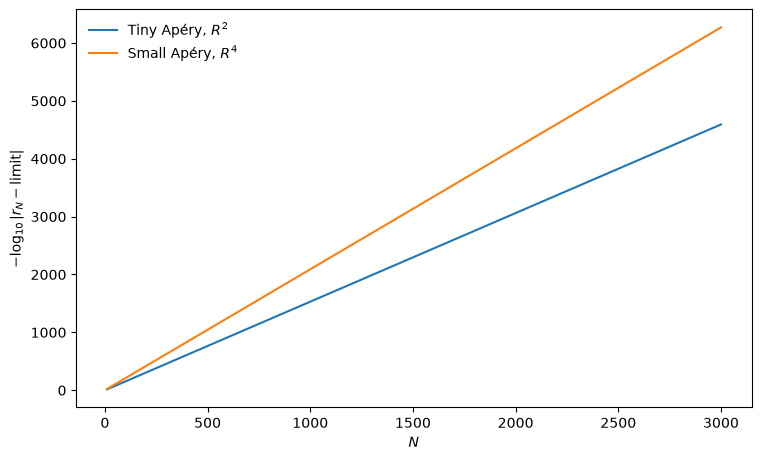

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 4.5), constrained_layout=True)
for name, (depths, values) in results.items():
    ax.plot(depths, values, label=name)
ax.set(xlabel="$N$", ylabel=r"$-\log_{10}|r_N-\mathrm{limit}|$")
ax.legend(frameon=False)
plt.show()